# EDA: why we built a separation score

This notebook walks through the data exploration that led to **Open but Ignored**, a separation-based metric for receivers who were open past the first-down marker when the ball went elsewhere. Each section ends with what it told us about the next step.

1. What the data can and can't measure
2. Who runs routes and who gets the ball
3. Separation at the throw decides completions
4. Coverage and depth shape separation
5. Getting open is not the same as getting the ball
6. How often the open man is ignored, and what it costs
7. Ideas we tested and dropped
8. Decision

All tracking work uses the same code as the final project (`src/data.py`, `src/metric.py`). Run from the repo root; the first run builds `cache/` in about 10 seconds.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from src.data import DATA, load_tables, match_targets, routes_at_throw
from src.metric import build_plays, build_routes, set_open, situation_summary

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150, "display.precision", 3)
SKILL = ["WR", "TE", "RB"]
PAL = {"WR": "#4C72B0", "TE": "#DD8452", "RB": "#55A868"}

T = load_tables()
games, plays, players, scout = T["games"], T["plays"], T["players"], T["pffScoutingData"]

## 1. What the data can and can't measure

In [2]:
pd.DataFrame({
    "rows": [len(games), len(plays), len(players), len(scout), len(glob.glob(str(DATA / "tracking" / "*.csv")))],
    "what it is": ["games, Weeks 1-8 of 2021", "dropbacks (passes, sacks, scrambles)", "players",
                   "PFF role per player per play", "tracking files, one per game, 10 frames/s"],
}, index=["games", "plays", "players", "pffScoutingData", "tracking/"])

,rows,what it is
games,122,"games, Weeks 1-8 of 2021"
plays,8557,"dropbacks (passes, sacks, scrambles)"
players,1679,players
pffScoutingData,188254,PFF role per player per play
tracking/,122,"tracking files, one per game, 10 frames/s"


In [3]:
# How far past the throw (or sack) does tracking go? Check every play in the first 10 games.
gap = []
for f in sorted(glob.glob(str(DATA / "tracking" / "*.csv")))[:10]:
    t = pd.read_csv(f, usecols=["playId", "frameId", "event"])
    end = t[t.event.isin(["pass_forward", "autoevent_passforward", "qb_sack", "qb_strip_sack", "run"])].groupby("playId").frameId.min()
    gap.append((t.groupby("playId").frameId.max() - end).dropna())
gap = pd.concat(gap)
print(f"Frames recorded after the throw: min {gap.min():.0f}, max {gap.max():.0f} (10 frames = 1 s), over {len(gap)} plays")
print("Target column in plays.csv:", [c for c in plays.columns if "target" in c.lower()] or "none")
print("Coverage-assignment column in pffScoutingData.csv:", [c for c in scout.columns if "cover" in c.lower()] or "none")

Frames recorded after the throw: min 5, max 5 (10 frames = 1 s), over 769 plays
Target column in plays.csv: none
Coverage-assignment column in pffScoutingData.csv: none


**What this told us.** Tracking stops 0.5 s after every throw, so catch-point separation and yards after catch can't be measured. There is also no target column. Whatever we build has to be measured **at the moment the ball is thrown**, which is exactly when the QB makes his decision. We get the intended receiver from the play description.

In [4]:
tg = match_targets(plays, players, scout)
attempts = plays.passResult.isin(["C", "I", "IN"]).sum()
print(f"Intended receiver identified on {len(tg):,} of {attempts:,} pass attempts ({len(tg) / attempts:.1%}).")
print("The rest have no receiver in the description, e.g.:", plays[plays.passResult == "I"].playDescription.str.extract(r"(pass incomplete \w+ \w+\.)")[0].dropna().iloc[0])

Intended receiver identified on 7,288 of 7,565 pass attempts (96.3%).
The rest have no receiver in the description, e.g.: pass incomplete short right.


## 2. Who runs routes and who gets the ball

In [5]:
pos = players.set_index("nflId")[["displayName", "officialPosition"]]
r = routes_at_throw(scout).join(pos, on="nflId")
r = r.merge(tg.assign(targeted=1), on=["gameId", "playId", "nflId"], how="left").fillna({"targeted": 0})
r = r.merge(plays[["gameId", "playId", "passResult", "prePenaltyPlayResult", "yardsToGo", "pff_passCoverageType"]],
            on=["gameId", "playId"])
r = r[r.officialPosition.isin(SKILL)]
thrown = r[r.end_event.isin(["pass_forward", "autoevent_passforward"])]
tt = thrown[thrown.targeted == 1]

sk = scout.join(pos, on="nflId")
sk = sk[sk.officialPosition.isin(SKILL)]
pd.DataFrame({
    "snaps": sk.groupby("officialPosition").size(),
    "stays in to block": sk.groupby("officialPosition").pff_role.apply(lambda s: (s == "Pass Block").mean()),
    "routes": r.groupby("officialPosition").size(),
    "targets per route": thrown.groupby("officialPosition").targeted.mean(),
    "completion": tt.groupby("officialPosition").passResult.apply(lambda s: (s == "C").mean()),
    "yds per catch": tt[tt.passResult == "C"].groupby("officialPosition").prePenaltyPlayResult.mean(),
    "median depth at throw": r.groupby("officialPosition").depth.median(),
}).loc[SKILL]

,snaps,stays in to block,routes,targets per route,completion,yds per catch,median depth at throw
officialPosition,,,,,,,
WR,23078,0.002,22966,0.217,0.584,14.138,8.95
TE,10496,0.136,9035,0.195,0.668,10.997,5.72
RB,8593,0.181,6975,0.197,0.750,7.878,-0.20


**What this told us.** WRs, TEs and RBs are targeted at similar rates per route (roughly 1 in 5), but on very different throws. RBs are caught at the line of scrimmage (median depth about 0 yards) for short gains; WRs are 9 yards downfield. Any measure of "open" has to account for **where** the receiver is, not just how much space he has.

## 3. Separation at the throw decides completions

Separation = distance from the receiver to the nearest PFF coverage defender at the throw frame, with coordinates normalized so the offense always moves right.

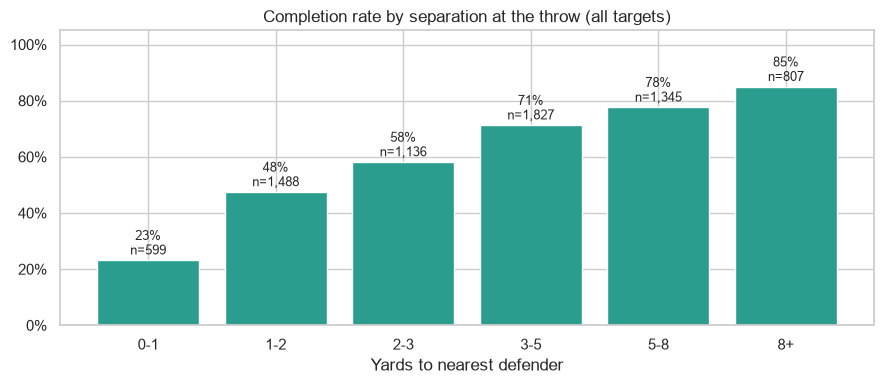

,targets,completion,interception
bucket,,,
0-1,599,0.232,0.035
1-2,1488,0.475,0.029
2-3,1136,0.582,0.039
3-5,1827,0.713,0.025
5-8,1345,0.777,0.018
8+,807,0.850,0.006


In [6]:
tt = tt.assign(bucket=pd.cut(tt.sep_throw, [0, 1, 2, 3, 5, 8, 60], labels=["0-1", "1-2", "2-3", "3-5", "5-8", "8+"]))
tab = tt.groupby("bucket", observed=True).agg(
    targets=("sep_throw", "size"),
    completion=("passResult", lambda s: (s == "C").mean()),
    interception=("passResult", lambda s: (s == "IN").mean()))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(tab.index.astype(str), tab.completion, color="#2a9d8f")
for i, (c, n) in enumerate(zip(tab.completion, tab.targets)):
    ax.text(i, c + 0.02, f"{c:.0%}\nn={n:,}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1.05)
ax.set(title="Completion rate by separation at the throw (all targets)", xlabel="Yards to nearest defender", ylabel="")
plt.tight_layout(); plt.show()
tab

**What this told us.** Separation at the throw is a strong, clean signal: completion rate climbs from about 23% inside 1 yard to about 85% beyond 8 yards, and interceptions fall from about 3.5% to under 1%. It's the right lens for the project.

## 4. Coverage and depth shape separation

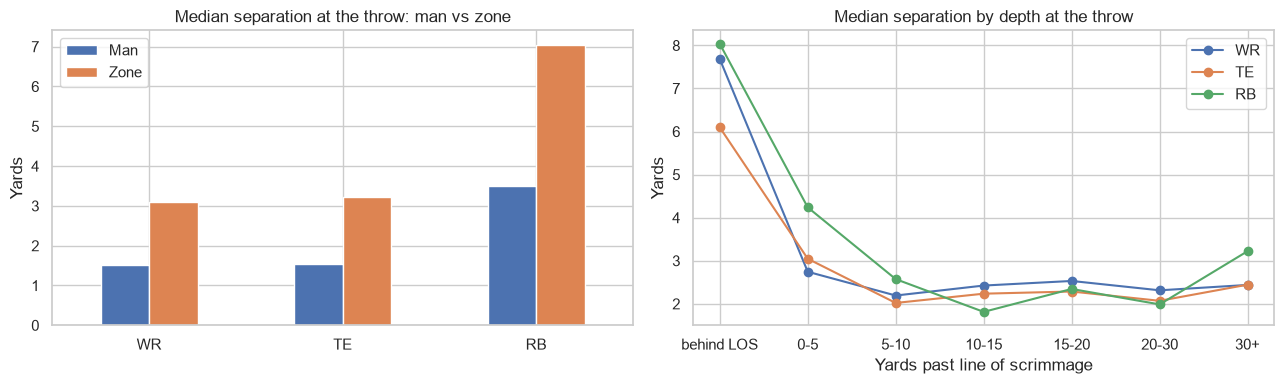

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mz = r[r.pff_passCoverageType.isin(["Man", "Zone"])]
mz.groupby(["officialPosition", "pff_passCoverageType"]).sep_throw.median().unstack().loc[SKILL].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Median separation at the throw: man vs zone", ylabel="Yards", xlabel=""); axes[0].legend(title="")

r["depth_bin"] = pd.cut(r.depth, [-15, 0, 5, 10, 15, 20, 30, 60],
                        labels=["behind LOS", "0-5", "5-10", "10-15", "15-20", "20-30", "30+"])
r.groupby(["depth_bin", "officialPosition"], observed=True).sep_throw.median().unstack()[SKILL].plot(
    ax=axes[1], marker="o", color=[PAL[p] for p in SKILL])
axes[1].set(title="Median separation by depth at the throw", xlabel="Yards past line of scrimmage", ylabel="Yards"); axes[1].legend(title="")
plt.tight_layout(); plt.show()

**What this told us.** Two things a separation metric must handle:
- Man coverage roughly halves separation for WRs and TEs, so "open" means different things against man and zone. We report results for both.
- Receivers behind or near the line are almost always open (median 6-8 yards of space behind the line of scrimmage). Counting those would flood the metric with checkdowns nobody cares about. We only count a receiver as open if he is **at or past the first-down marker**.

## 5. Getting open is not the same as getting the ball

Open rate = share of a player's routes with 3+ yards of separation at the throw, counted on every route, targeted or not. Players with 100+ routes.

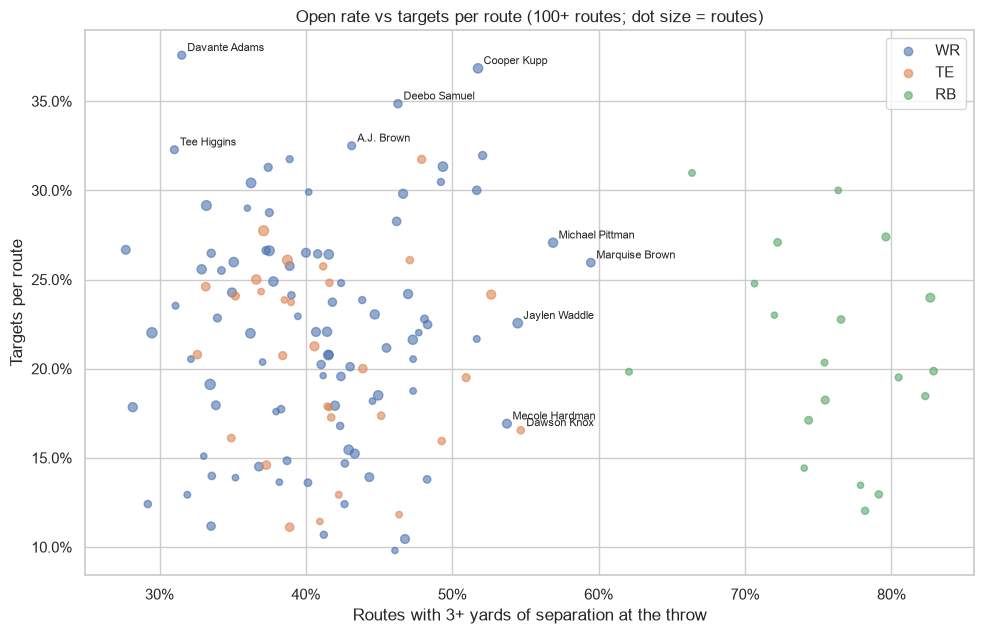

WR    0.10
TE   -0.11
RB   -0.28
Name: correlation: open rate vs target rate, dtype: float64

In [8]:
pl = thrown.groupby(["nflId", "displayName", "officialPosition"]).agg(
    routes=("sep_throw", "size"), target_rate=("targeted", "mean"),
    open_rate=("sep_throw", lambda s: (s >= 3).mean())).reset_index()
q = pl[pl.routes >= 100]

fig, ax = plt.subplots(figsize=(10, 6.5))
for p in SKILL:
    d = q[q.officialPosition == p]
    ax.scatter(d.open_rate, d.target_rate, s=d.routes / 5, alpha=0.6, color=PAL[p], label=p)
lab = pd.concat([q.nlargest(5, "target_rate"), q[q.officialPosition != "RB"].nlargest(5, "open_rate")]).drop_duplicates("nflId")
for _, row in lab.iterrows():
    ax.annotate(row.displayName, (row.open_rate, row.target_rate), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Open rate vs targets per route (100+ routes; dot size = routes)",
       xlabel="Routes with 3+ yards of separation at the throw", ylabel="Targets per route")
ax.legend(); plt.tight_layout(); plt.show()
pd.Series({p: q[q.officialPosition == p][["open_rate", "target_rate"]].corr().iloc[0, 1] for p in SKILL},
          name="correlation: open rate vs target rate").round(2)

**What this told us.** Across players, being open barely predicts being targeted: the correlation is weak for WRs (0.10) and negative for TEs (−0.11) and RBs (−0.28). Some of that is defenses leaving low-threat players alone, and some is QBs throwing to their stars into tight windows. Either way, **a lot of open receivers don't get the ball**. That raised the question the project answers: how often is a receiver open in a useful spot while the ball goes elsewhere, and what does it cost?

## 6. How often the open man is ignored, and what it costs

Using the final project's definition (`src/metric.py`): a receiver is **open downfield** if he is 3+ yards from the nearest defender at the throw **and** 0.5 s before it, at or past the first-down marker. A play is a **miss** when someone was open downfield and the targeted receiver was not.

Why the 0.5 s check: some receivers only come free as the ball leaves the QB's hand, too late to be a real option.

In [9]:
rr = build_routes(T)
open_now = (rr.sep_throw >= 3) & rr.past_sticks
print(f"Routes open past the sticks at the throw that were NOT open 0.5 s earlier: "
      f"{(rr.loc[open_now, 'sep_pre'] < 3).mean():.0%}. The 0.5 s check removes these.")

p = build_plays(rr)
s = situation_summary(p)
print(f"\n{len(p):,} thrown passes with an identified target; open man ignored on {p.miss.mean():.0%} of them\n")
s[["plays", "first_down", "completion", "yards", "target_depth", "pressured"]]

Routes open past the sticks at the throw that were NOT open 0.5 s earlier: 23%. The 0.5 s check removes these.

7,264 thrown passes with an identified target; open man ignored on 23% of them



,plays,first_down,completion,yards,target_depth,pressured
situation,,,,,,
Threw to the open man,856,0.634,0.664,11.697,11.96,0.347
Open man ignored,1649,0.363,0.645,7.284,4.72,0.351
No open option past the sticks,4759,0.329,0.622,7.047,5.14,0.269


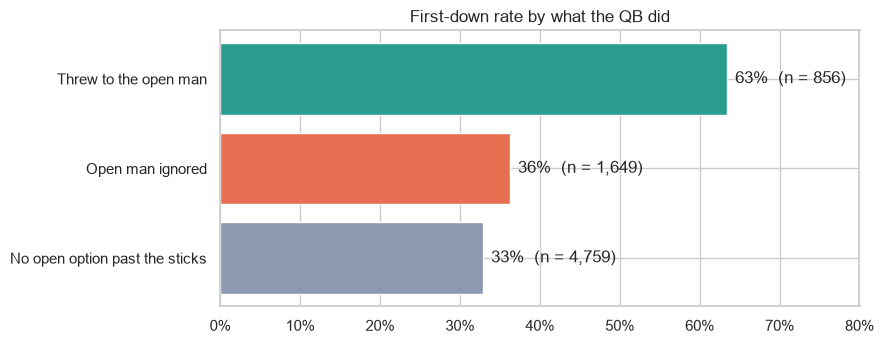

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = ["#2a9d8f", "#e76f51", "#8d99ae"]
ax.barh(s.index, s.first_down, color=colors)
for i, v in enumerate(s.first_down):
    ax.text(v + 0.01, i, f"{v:.0%}  (n = {s.plays.iloc[i]:,})", va="center")
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlim(0, 0.8)
ax.set(title="First-down rate by what the QB did", xlabel="")
plt.tight_layout(); plt.show()

**What this told us.** About 1 in 4 throws leaves an open receiver past the sticks. Those throws convert about as often as plays with no open option at all (36% vs 33%), while throwing to the open man converts 63%. Completion rates barely differ, so the cost shows up in **first downs**, not incompletions. Pressure is about the same in both groups (about 35%), so it doesn't explain the gap.

In [11]:
rows = []
for yds in (2, 3, 4, 5):
    pp = build_plays(set_open(rr, yds))
    fd = pp.groupby("situation").first_down.mean()
    rows.append({"open threshold (yds)": yds, "miss share": pp.miss.mean(),
                 "first downs: threw to open man": fd["Threw to the open man"],
                 "first downs: open man ignored": fd["Open man ignored"]})
pd.DataFrame(rows).set_index("open threshold (yds)")

,miss share,first downs: threw to open man,first downs: open man ignored
open threshold (yds),,,
2,0.321,0.594,0.344
3,0.227,0.634,0.363
4,0.142,0.668,0.376
5,0.070,0.672,0.385


The gap holds whether "open" means 2, 3, 4 or 5 yards, so the finding doesn't depend on the threshold we picked.

## 7. Ideas we tested and dropped

### a. Chip blocks by TEs and RBs
Does a TE or RB chipping a pass rusher before his route protect the QB?

In [12]:
press = scout.groupby(["gameId", "playId"])[["pff_hit", "pff_hurry", "pff_sack"]].max().fillna(0).max(axis=1).rename("pressured")
chip = scout[scout.pff_blockType == "CH"].groupby(["gameId", "playId"]).size().rename("chips")
c = press.to_frame().join(chip).fillna(0)
c.groupby(c.chips > 0).pressured.agg(["size", "mean"]).rename(index={False: "no chip", True: "chip on the play"},
                                                              columns={"size": "plays", "mean": "pressure rate"})

,plays,pressure rate
chips,,
no chip,7216,0.364
chip on the play,1341,0.440


Plays with a chip show **more** pressure, not less. Offenses most likely chip against their toughest rushers and on longer-developing plays, so the chip's own effect can't be separated from why it was called. **Dropped:** too confounded to answer in 3 hours.

### b. Linebacker mismatches on TEs and RBs (`plan.md`)
In man coverage, do TEs and RBs get more space against linebackers than against defensive backs?

In [13]:
dgrp = lambda p: "LB" if p in ("ILB", "OLB", "MLB", "LB") else ("DB" if p in ("CB", "FS", "SS", "DB") else "other")
man = r[(r.pff_passCoverageType == "Man") & r.officialPosition.isin(["TE", "RB"])].copy()
man["defender"] = man.defId.map(players.set_index("nflId").officialPosition).map(dgrp)
man[man.defender != "other"].groupby(["officialPosition", "defender"]).sep_throw.agg(["size", "median"]).rename(
    columns={"size": "routes", "median": "median separation (yds)"})

routes  median separation (yds)
officialPosition defender                                 
RB               DB           520                    4.519
                 LB          1321                    3.322
TE               DB          1881                    1.479
                 LB           674                    1.722

TEs get only about a quarter-yard more space against linebackers (nearest-defender proxy), and RBs get *less*. The signal is small and depends on inferring who covers whom. **Parked:** it needs the full matching method in `plan.md` to be convincing.

### c. A plain "open score" for receivers
Grading receivers on how often they get open is already published: ESPN's [Receiver Tracking Metrics](https://www.espn.com/nfl/story/_/id/34649390/espn-receiver-tracking-metrics-how-new-nfl-stats-work-open-catch-yac-scores) include an Open Score computed on every route, targeted or not. **Changed angle:** instead of grading how often a receiver gets open, we measure what happens when an open receiver is **not used**. That grades the decision and puts a first-down cost on it, which Section 6 shows is large.

## 8. Decision

| Finding | Effect on the design |
|---|---|
| Tracking ends 0.5 s after the throw; no target column | Measure everything at the throw; parse the target from the play description |
| Separation at the throw drives completion (23% to 85%) | Separation is the core signal |
| Receivers near the line are almost always open | Only count receivers at or past the first-down marker |
| Some receivers come open only as the ball leaves | Also require 3+ yards 0.5 s before the throw |
| Man coverage halves separation | Report man and zone separately |
| Open receivers often don't get the ball | Measure the cost of ignoring them |
| Ignoring the open man costs about 27 points of first-down rate, at any threshold | This is the headline |

The full pipeline, charts and player and QB tables are produced by `python -m src.run`.